# Modelo paramétrico: funciones discriminantes gaussianas (LDA y QDA)

Pasos:
1. Cargar datos y partición train/test estratificada (el test no se toca hasta el final).
2. Búsqueda de hiperparámetros con validación cruzada estratificada (solo sobre train).
3. Comparar dos conjuntos de variables: `todas` vs `sin_redundantes` (sin AFR y Speed).
4. Reportar train / validación (CV con IC 95%) / test (bootstrap con IC 95%).

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings('ignore')
SEED = 42

## 1. Carga de datos

In [2]:

if not os.path.exists('EngineFaultDB_Final.csv'):
    from google.colab import files
    files.upload()

df = pd.read_csv('EngineFaultDB_Final.csv')
print('Forma:', df.shape)
print('Datos faltantes:', int(df.isna().sum().sum()))
print(df['Fault'].value_counts(normalize=True).sort_index().round(4))

# Pares casi perfectamente correlacionados (colinealidad)
print('\nCorr Lambda-AFR:', round(df['Lambda'].corr(df['AFR']), 4))
print('Corr Speed-RPM :', round(df['Speed'].corr(df['RPM']), 4))

Saving EngineFaultDB_Final.csv to EngineFaultDB_Final.csv
Forma: (55999, 15)
Datos faltantes: 0
Fault
0    0.2857
1    0.1964
2    0.2679
3    0.2500
Name: proportion, dtype: float64

Corr Lambda-AFR: 1.0
Corr Speed-RPM : 0.9969


## 2. Partición y configuración de la validación

In [3]:
X = df.drop(columns='Fault')
y = df['Fault']

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Train:', X_tr.shape, ' Test:', X_te.shape)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

FEATURE_SETS = {
    'todas': list(X.columns),
    'sin_redundantes': [c for c in X.columns if c not in ['AFR', 'Speed']],
}
for k, v in FEATURE_SETS.items():
    print(k, len(v), 'variables')

Train: (44799, 14)  Test: (11200, 14)
todas 14 variables
sin_redundantes 12 variables


## 3. Búsqueda de hiperparámetros

El escalador queda dentro del `Pipeline`, así que se ajusta solo con el train de cada fold (sin fuga de información).

- **LDA**: `solver='svd'` (sin regularización) y `solver='lsqr'` con `shrinkage`.
- **QDA**: `reg_param` (regulariza las covarianzas por clase, clave por la colinealidad).

In [4]:
MODELS = {
    'LDA': (LDA(), [
        {'clf__solver': ['svd']},
        {'clf__solver': ['lsqr'], 'clf__shrinkage': [None, 'auto', 0.1, 0.3, 0.5, 0.7, 0.9]},
    ]),
    'QDA': (QDA(), [
        {'clf__reg_param': [0.0, 0.001, 0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]},
    ]),
}

searches, rows = {}, []
for model_name, (clf, grid) in MODELS.items():
    for fs_name, cols in FEATURE_SETS.items():
        pipe = Pipeline([('scaler', StandardScaler()), ('clf', clf)])
        gs = GridSearchCV(pipe, grid, cv=cv, scoring='f1_macro', refit=True,
                          return_train_score=True, n_jobs=-1)
        gs.fit(X_tr[cols], y_tr)
        searches[(model_name, fs_name)] = gs
        i = gs.best_index_
        rows.append({'modelo': model_name, 'variables': fs_name,
                     'mejores_params': gs.best_params_,
                     'F1_macro_train': gs.cv_results_['mean_train_score'][i],
                     'F1_macro_val': gs.cv_results_['mean_test_score'][i],
                     'std_val': gs.cv_results_['std_test_score'][i]})

resumen = pd.DataFrame(rows)
resumen.round(4)

,modelo,variables,mejores_params,F1_macro_train,F1_macro_val,std_val
0,LDA,todas,"{'clf__shrinkage': 0.1, 'clf__solver': 'lsqr'}",0.5542,0.5531,0.0065
1,LDA,sin_redundantes,"{'clf__shrinkage': 0.1, 'clf__solver': 'lsqr'}",0.5567,0.5555,0.0060
2,QDA,todas,{'clf__reg_param': 0.001},0.6543,0.6526,0.0030
3,QDA,sin_redundantes,{'clf__reg_param': 0.0},0.6512,0.6502,0.0038


### Efecto de los hiperparámetros (para el informe)

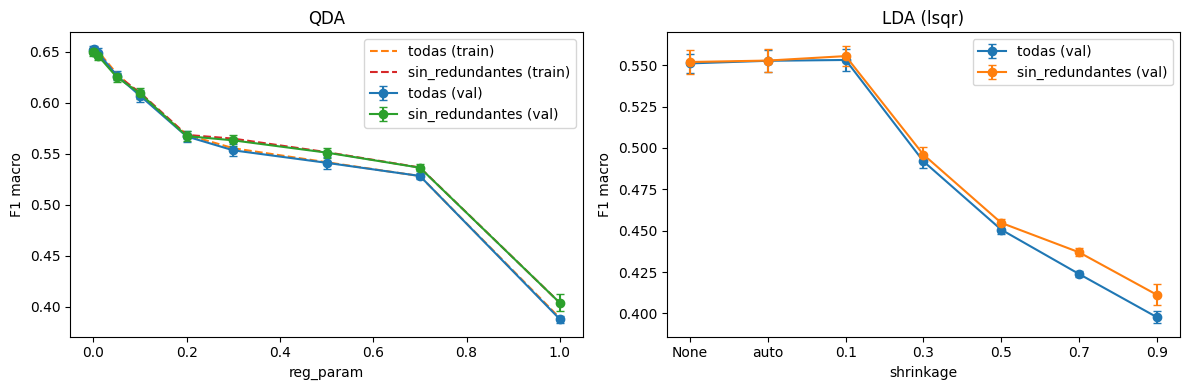

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# QDA: reg_param vs F1 macro
for fs_name in FEATURE_SETS:
    r = pd.DataFrame(searches[('QDA', fs_name)].cv_results_)
    axes[0].errorbar(r['param_clf__reg_param'].astype(float), r['mean_test_score'],
                     yerr=r['std_test_score'], marker='o', capsize=3, label=f'{fs_name} (val)')
    axes[0].plot(r['param_clf__reg_param'].astype(float), r['mean_train_score'],
                 '--', label=f'{fs_name} (train)')
axes[0].set_xlabel('reg_param'); axes[0].set_ylabel('F1 macro'); axes[0].set_title('QDA'); axes[0].legend()

# LDA: shrinkage vs F1 macro (solo solver lsqr)
for fs_name in FEATURE_SETS:
    r = pd.DataFrame(searches[('LDA', fs_name)].cv_results_)
    r = r[r['param_clf__solver'] == 'lsqr'].reset_index(drop=True)
    etiquetas = [str(v) for v in r['param_clf__shrinkage'].tolist()]
    axes[1].errorbar(range(len(r)), r['mean_test_score'].to_numpy(), yerr=r['std_test_score'].to_numpy(),
                     marker='o', capsize=3, label=f'{fs_name} (val)')
axes[1].set_xticks(range(len(etiquetas))); axes[1].set_xticklabels(etiquetas)
axes[1].set_xlabel('shrinkage'); axes[1].set_ylabel('F1 macro'); axes[1].set_title('LDA (lsqr)'); axes[1].legend()
plt.tight_layout(); plt.show()

## 4. Resultados finales con intervalos de confianza

- **Train / Validación**: validación cruzada 5-fold sobre el train con el mejor modelo. IC 95% con distribución t sobre los folds.
- **Test**: se evalúa una sola vez; IC 95% por bootstrap (1000 remuestreos).

In [8]:
def ic_t(scores, conf=0.95):
    scores = np.asarray(scores)
    m, se = scores.mean(), stats.sem(scores)
    h = se * stats.t.ppf((1 + conf) / 2, len(scores) - 1)
    return m, m - h, m + h

def ic_boot(y_true, y_pred, metric, n=1000):
    rng = np.random.default_rng(SEED)
    yt, yp = np.asarray(y_true), np.asarray(y_pred)
    vals = []
    for _ in range(n):
        s = rng.choice(len(yt), len(yt))
        vals.append(metric(yt[s], yp[s]))
    return np.mean(vals), *np.percentile(vals, [2.5, 97.5])

f1m = lambda a, b: f1_score(a, b, average='macro')
precm = lambda a, b: precision_score(a, b, average='macro')
recm = lambda a, b: recall_score(a, b, average='macro')

final = []
for (model_name, fs_name), gs in searches.items():
    cols = FEATURE_SETS[fs_name]
    cvres = cross_validate(gs.best_estimator_, X_tr[cols], y_tr, cv=cv, n_jobs=-1,
                           scoring={'acc': 'accuracy', 'f1': 'f1_macro', 'prec': 'precision_macro', 'rec': 'recall_macro'},
                           return_train_score=True)
    y_pred = gs.best_estimator_.predict(X_te[cols])
    row = {'modelo': model_name, 'variables': fs_name}

    # Guardar métricas de Train y Validación con intervalos t
    for etiqueta, clave in [('train', 'train_'), ('val', 'test_')]:
        for met in ['acc', 'f1', 'prec', 'rec']:
            m, lo, hi = ic_t(cvres[clave + met])
            row[f'{met}_{etiqueta}'] = f'{m:.4f} [{lo:.4f}, {hi:.4f}]'

    # Guardar métricas de Test con bootstrap
    for met, fn in [('acc', accuracy_score), ('f1', f1m), ('prec', precm), ('rec', recm)]:
        m, lo, hi = ic_boot(y_te, y_pred, fn)
        row[f'{met}_test'] = f'{m:.4f} [{lo:.4f}, {hi:.4f}]'

    final.append(row)

tabla_final = pd.DataFrame(final)
pd.set_option('display.max_columns', None)
display(tabla_final)

,modelo,variables,acc_train,f1_train,prec_train,rec_train,acc_val,f1_val,prec_val,rec_val,acc_test,f1_test,prec_test,rec_test
0,LDA,todas,"0.5536 [0.5518, 0.5554]","0.5542 [0.5523, 0.5561]","0.5677 [0.5657, 0.5697]","0.5491 [0.5470, 0.5511]","0.5525 [0.5436, 0.5615]","0.5531 [0.5441, 0.5622]","0.5667 [0.5560, 0.5774]","0.5480 [0.5397, 0.5563]","0.5576 [0.5488, 0.5665]","0.5595 [0.5502, 0.5686]","0.5733 [0.5644, 0.5827]","0.5535 [0.5444, 0.5625]"
1,LDA,sin_redundantes,"0.5561 [0.5538, 0.5583]","0.5567 [0.5545, 0.5589]","0.5708 [0.5687, 0.5730]","0.5514 [0.5489, 0.5538]","0.5549 [0.5465, 0.5634]","0.5555 [0.5472, 0.5638]","0.5697 [0.5601, 0.5794]","0.5502 [0.5424, 0.5580]","0.5594 [0.5504, 0.5684]","0.5616 [0.5521, 0.5711]","0.5762 [0.5669, 0.5855]","0.5553 [0.5462, 0.5644]"
2,QDA,todas,"0.6706 [0.6695, 0.6718]","0.6543 [0.6533, 0.6554]","0.6867 [0.6851, 0.6883]","0.6908 [0.6897, 0.6920]","0.6692 [0.6656, 0.6728]","0.6526 [0.6484, 0.6567]","0.6847 [0.6789, 0.6906]","0.6895 [0.6858, 0.6931]","0.6733 [0.6637, 0.6819]","0.6572 [0.6489, 0.6652]","0.6878 [0.6788, 0.6968]","0.6936 [0.6869, 0.6999]"
3,QDA,sin_redundantes,"0.6681 [0.6675, 0.6687]","0.6512 [0.6506, 0.6517]","0.6835 [0.6822, 0.6847]","0.6889 [0.6883, 0.6895]","0.6672 [0.6627, 0.6716]","0.6502 [0.6450, 0.6555]","0.6823 [0.6751, 0.6896]","0.6879 [0.6835, 0.6923]","0.6685 [0.6589, 0.6769]","0.6519 [0.6434, 0.6601]","0.6820 [0.6728, 0.6917]","0.6896 [0.6833, 0.6963]"


## 5. Mejor modelo: matriz de confusión y reporte por clase (test)

Mejor configuración: ('QDA', 'todas') {'clf__reg_param': 0.001}
              precision    recall  f1-score   support

           0     0.9912    0.7788    0.8722      3200
           1     0.7370    0.9655    0.8359      2200
           2     0.5244    0.2110    0.3009      3000
           3     0.4990    0.8193    0.6203      2800

    accuracy                         0.6735     11200
   macro avg     0.6879    0.6936    0.6573     11200
weighted avg     0.6932    0.6735    0.6491     11200



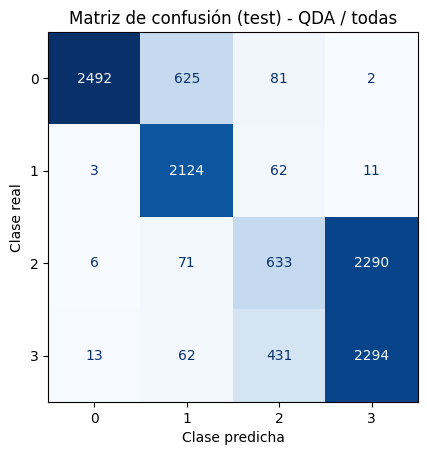

In [7]:
mejor_key = max(searches, key=lambda k: searches[k].best_score_)
mejor = searches[mejor_key]
cols = FEATURE_SETS[mejor_key[1]]
print('Mejor configuración:', mejor_key, mejor.best_params_)

y_pred = mejor.best_estimator_.predict(X_te[cols])
print(classification_report(y_te, y_pred, digits=4))

ConfusionMatrixDisplay.from_predictions(y_te, y_pred, cmap='Blues', colorbar=False)
plt.title(f'Matriz de confusión (test) - {mejor_key[0]} / {mejor_key[1]}')
plt.xlabel('Clase predicha'); plt.ylabel('Clase real'); plt.show()

### 6. Interpretación de Resultados del Modelo de Diagnóstico de Fallos

#### A. Comparación General y Rendimiento (LDA vs. QDA)
* **Superioridad de QDA:** El modelo **QDA** supera de manera consistente a LDA en todas las pruebas. El mejor F1-macro en test del QDA alcanza **~0.6572**, mientras que el de LDA queda rezagado en **~0.5595**.
* **Significado Físico/Matemático:** Esto indica claramente que las fronteras de decisión entre los tipos de fallos son **no lineales**. QDA se adapta mucho mejor al asumir que cada clase tiene su propia matriz de covarianza, lo cual captura la curvatura y las interacciones complejas de los sensores del motor.

#### B. Impacto de la Redundancia de Variables
* **Colinealidad:** En el análisis exploratorio observamos correlaciones extremas (Lambda-AFR = 1.0 y Speed-RPM = 0.9969).
* **Comportamiento en QDA:** Al eliminar `AFR` y `Speed` (conjunto `sin_redundantes`), el F1-macro en test baja ligeramente de **0.6572** a **0.6519**. El modelo completo (`todas`) se beneficia del parámetro de regularización óptimo obtenido (`reg_param: 0.001`), permitiendo mantener toda la información sin verse afectado negativamente por la redundancia.
* **Comportamiento en LDA:** LDA mejora levemente con la remoción de las variables colineales (de **0.5595** a **0.5616**), ya que es intrínsecamente más sensible a la colinealidad exacta.

#### C. Análisis de Generalización (Overfitting)
Al comparar los intervalos de confianza del mejor modelo (**QDA, todas**):
* **F1-macro Train:** `0.6543 [0.6533, 0.6554]`
* **F1-macro Val:** `0.6526 [0.6484, 0.6567]`
* **F1-macro Test:** `0.6572 [0.6489, 0.6652]`

El solapamiento casi perfecto entre las tres fases indica una **excelente capacidad de generalización** y descarta cualquier sospecha de overfitting.

#### D. Diagnóstico Detallado por Tipo de Fallo (Test - QDA Todas)

* **Clase 0 (Sin Fallo / Estado Normal):**
  * **Precisión: 99.12% | Recall: 77.88%**
  * *Análisis:* Si el sistema clasifica un estado como normal, la probabilidad de acierto es casi perfecta (bajísimos falsos positivos). Sin embargo, un ~22% de los estados normales reales son etiquetados erróneamente como fallos (principalmente Clase 3), lo que genera falsas alarmas.

* **Clase 1:**
  * **Precisión: 73.70% | Recall: 96.55%**
  * *Análisis:* Excelente capacidad de detección. Casi ningún fallo de tipo 1 se le escapa al modelo.

* **Clase 2:**
  * **Precisión: 52.44% | Recall: 21.10%**
  * *Análisis:* **Es el punto crítico de mejora.** El modelo es incapaz de identificar adecuadamente la clase 2, confundiéndola de forma sistemática con la Clase 3.

* **Clase 3:**
  * **Precisión: 49.90% | Recall: 81.93%**
  * *Análisis:* Funciona como un sumidero de predicciones ("cajón de sastre"). Capta muchos fallos reales de Clase 3, pero tiene un volumen muy alto de falsos positivos procedentes de la Clase 0 y 2.
